In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('orders.csv')
df.head(6)

,Order Id,Order Date,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub Category,Product Id,cost price,List Price,Quantity,Discount Percent
0,1,2023-03-01,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,FUR-BO-10001798,240,260,2,2
1,2,2023-08-15,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,FUR-CH-10000454,600,730,3,3
2,3,2023-01-10,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,OFF-LA-10000240,10,10,2,5
3,4,2022-06-18,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,FUR-TA-10000577,780,960,5,2
4,5,2022-07-13,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,OFF-ST-10000760,20,20,2,5
5,6,2022-03-13,Not Available,Consumer,United States,Los Angeles,California,90032,West,Furniture,Furnishings,FUR-FU-10001487,50,50,7,3


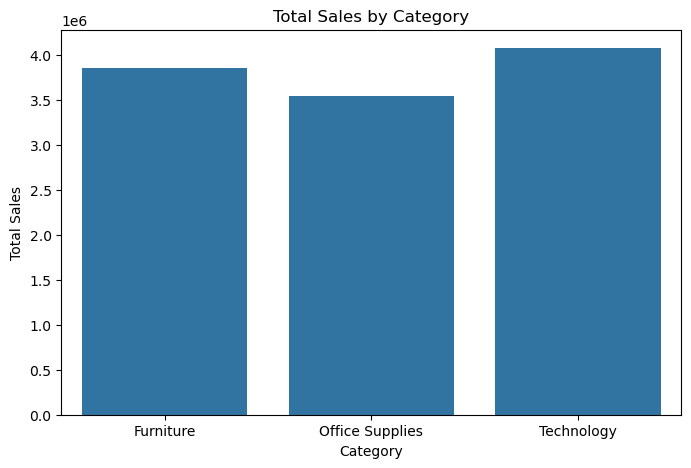

In [3]:
df['Sales'] = df['List Price'] * df['Quantity']  # create sales column

category_sales = df.groupby('Category')['Sales'].sum().reset_index()

plt.figure(figsize=(8,5))
sns.barplot(data=category_sales, x='Category', y='Sales')
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.show()

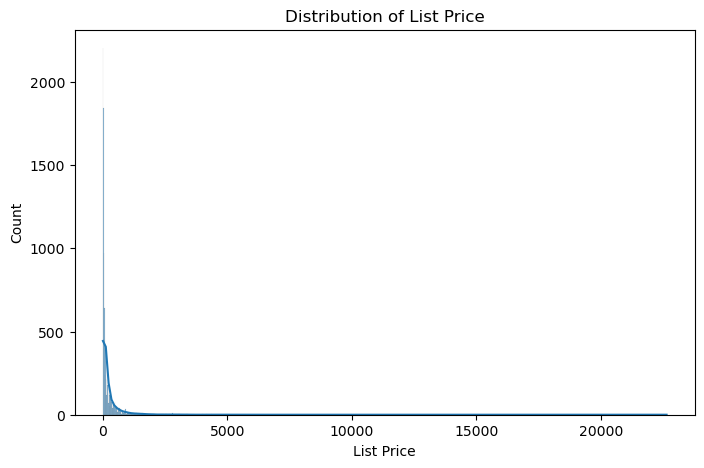

In [4]:
plt.figure(figsize=(8,5))
sns.histplot(df['List Price'], kde=True)
plt.title("Distribution of List Price")
plt.xlabel("List Price")
plt.ylabel("Count")
plt.show()


In [5]:
'''plt.figure(figsize=(10,10))
sns.countplot(data=df, y='State', order=df['State'].value_counts().index)
plt.title("Number of Orders by State")
plt.xlabel("Order Count")
plt.ylabel("State")
plt.show()'''


'plt.figure(figsize=(10,10))\nsns.countplot(data=df, y=\'State\', order=df[\'State\'].value_counts().index)\nplt.title("Number of Orders by State")\nplt.xlabel("Order Count")\nplt.ylabel("State")\nplt.show()'

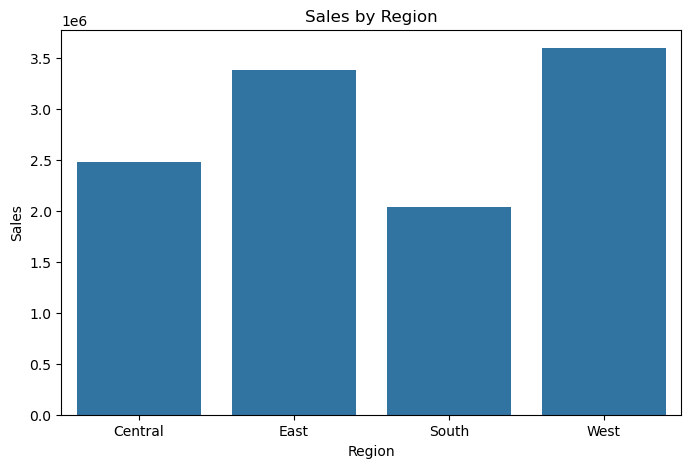

In [6]:
region_sales = df.groupby('Region')['Sales'].sum().reset_index()

plt.figure(figsize=(8,5))
sns.barplot(data=region_sales, x='Region', y='Sales')
plt.title("Sales by Region")
plt.show()


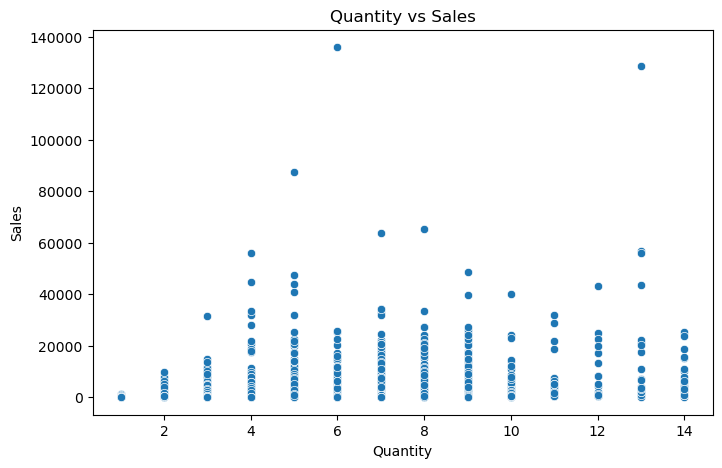

In [7]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='Quantity', y='Sales')
plt.title("Quantity vs Sales")
plt.xlabel("Quantity")
plt.ylabel("Sales")
plt.show()


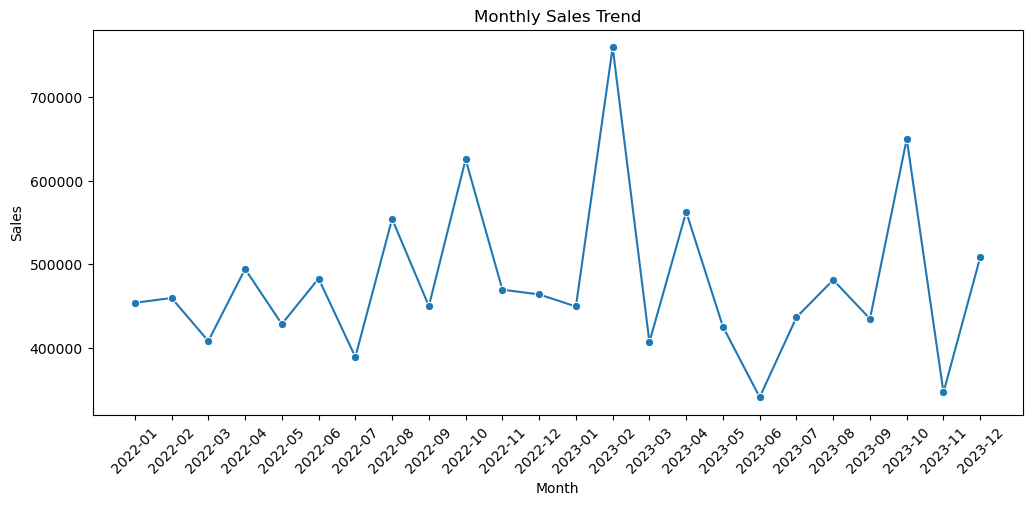

In [8]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Month'] = df['Order Date'].dt.to_period('M').astype(str)

monthly_sales = df.groupby('Month')['Sales'].sum().reset_index()

plt.figure(figsize=(12,5))
sns.lineplot(data=monthly_sales, x='Month', y='Sales', marker='o')
plt.xticks(rotation=45)
plt.title("Monthly Sales Trend")
plt.show()

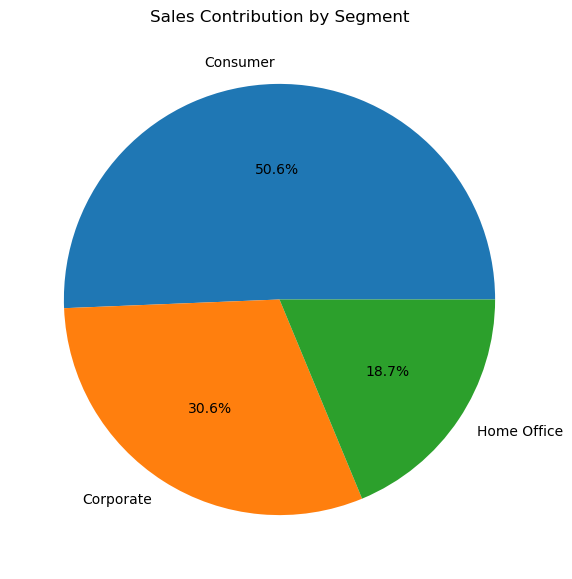

In [9]:
segment_sales = df.groupby('Segment')['Sales'].sum()

plt.figure(figsize=(7,7))
plt.pie(segment_sales, labels=segment_sales.index, autopct='%1.1f%%')
plt.title("Sales Contribution by Segment")
plt.show()


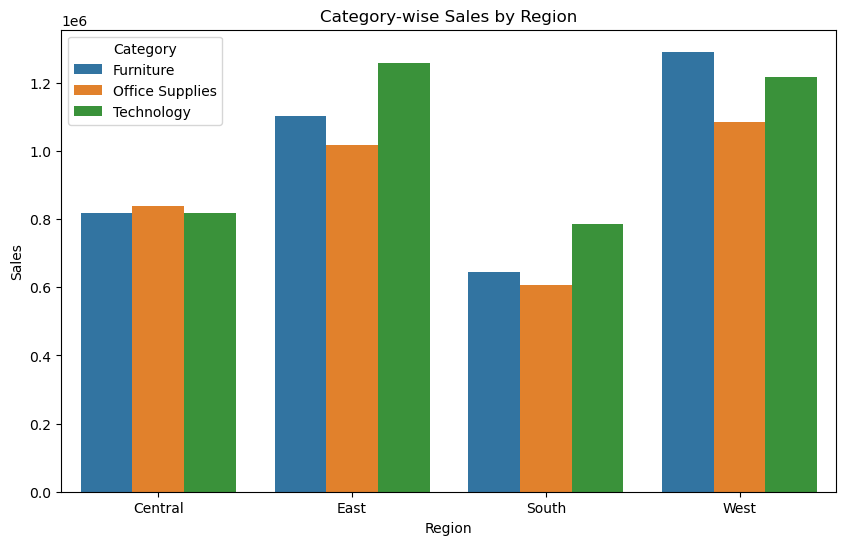

In [10]:
cat_reg = df.groupby(['Region', 'Category'])['Sales'].sum().reset_index()

plt.figure(figsize=(10,6))
sns.barplot(data=cat_reg, x='Region', y='Sales', hue='Category')
plt.title("Category-wise Sales by Region")
plt.show()


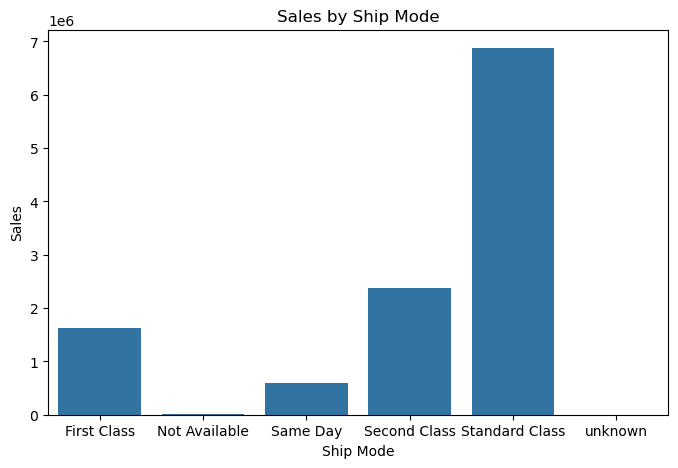

In [11]:
ship_sales = df.groupby('Ship Mode')['Sales'].sum().reset_index()

plt.figure(figsize=(8,5))
sns.barplot(data=ship_sales, x='Ship Mode', y='Sales')
plt.title("Sales by Ship Mode")
plt.show()
